In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
data = pd.read_csv("House_Pricing_Regression_300_Rows.csv")

data.head(300)

FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/USER/python/House_Pricing_Regression_300_Rows.csv.xls'

In [ ]:
data.describe()

,House_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Location_Score,Parking_Spaces,Price_NGN
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,3.000000e+02
mean,150.500000,2649.990000,3.726667,2.723333,21.033333,5.353333,2.360000,5.676023e+08
std,86.746758,1086.458524,1.572747,1.224112,11.713650,2.891891,1.126037,2.104644e+08
min,1.000000,651.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.687000e+08
25%,75.750000,1741.750000,2.000000,2.000000,11.000000,3.000000,2.000000,3.963500e+08
50%,150.500000,2618.000000,4.000000,3.000000,22.000000,5.000000,2.000000,5.514500e+08
75%,225.250000,3603.000000,5.000000,4.000000,32.000000,8.000000,3.000000,7.537250e+08
max,300.000000,4493.000000,6.000000,5.000000,40.000000,10.000000,4.000000,9.423000e+08


In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   House_ID        300 non-null    int64
 1   Area_sqft       300 non-null    int64
 2   Bedrooms        300 non-null    int64
 3   Bathrooms       300 non-null    int64
 4   Age_years       300 non-null    int64
 5   Location_Score  300 non-null    int64
 6   Parking_Spaces  300 non-null    int64
 7   Price_NGN       300 non-null    int64
dtypes: int64(8)
memory usage: 18.9 KB


In [ ]:
data.isnull().sum()

House_ID          0
Area_sqft         0
Bedrooms          0
Bathrooms         0
Age_years         0
Location_Score    0
Parking_Spaces    0
Price_NGN         0
dtype: int64

In [ ]:
X = data.drop(columns=["House_ID", "Price_NGN"])
y = data["Price_NGN"]

In [ ]:
#to verify the selection
print("Input features:")
print(X.columns.tolist())

print("/nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_years', 'Location_Score', 'Parking_Spaces']
/nInput shape: (300, 6)
Target shape: (300,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 181539.49,1518205.21,8660096.68,-509649.04,8094347.92, 861498. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Area_sqft','Bedrooms','Bathrooms','Age_years','Location_Score', 'Parking_Spaces']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.293e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [ ]:
# Predict prices based on the hidden test features
y_pred = model.predict(X_test)

In [ ]:
# Calculate the R-squared score
score = r2_score(y_test, y_pred)
print(f"Model R-squared Score: {score:.4f}")

Model R-squared Score: 0.9870


In [ ]:
# Calculate the R-squared score
score = r2_score(y_test, y_pred)
print(f"Model R-squared Score: {score:.4f}")

Model R-squared Score: 0.9870


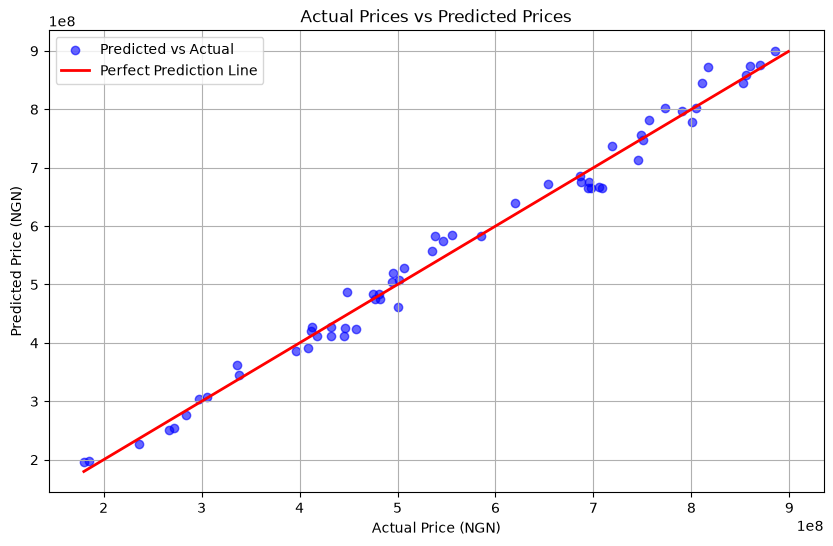

In [ ]:
plt.figure(figsize=(10, 6))

# Plot the actual values vs predicted values as a scatter plot
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predicted vs Actual')

# Draw a red diagonal line representing a perfect prediction (y = x)
# We find the min and max of the actual prices to draw the line across the graph
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linewidth=2, label='Perfect Prediction Line')

plt.title('Actual Prices vs Predicted Prices')
plt.xlabel('Actual Price (NGN)')
plt.ylabel('Predicted Price (NGN)')
plt.legend()
plt.grid(True)
plt.show()